# Parte 3 - perfis de pobreza por clusterização
## Contexto, objetivo e perguntas
**Título:** Pobreza e desigualdades no Brasil: indicadores e perfis de vulnerabilidade.
O objetivo é segmentar perfis agregados por semelhança das taxas, como apoio exploratório à comunicação de desigualdades. Pergunta: quais recortes de 2022 apresentam níveis semelhantes de pobreza e extrema pobreza? Perguntas secundárias: a segmentação muda com o algoritmo? É estável às inicializações e à escala?

Escolhemos aprendizado não supervisionado, sem variável alvo. Não há rótulos de “vulnerabilidade verdadeira”, renda individual ou base adequada para prever elegibilidade de pessoas. Treinamos **K-means e DBSCAN**, conforme a aula 15. AutoGluon não é obrigatório no enunciado e o exemplo supervisionado da aula não se ajusta a esta tarefa.

**Unidade de análise:** 20 perfis de segmento × sexo de 2022 (10 segmentos × 2 sexos), excluindo Total de sexo e Total nacional para não incluir diretamente suas médias como novos perfis. As sobreposições entre dimensões permanecem. É uma demonstração exploratória pequena, não uma amostra independente de indivíduos.


In [1]:
from pathlib import Path
import json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings('ignore', message='.*xlrd engine.*')
ROOT = Path.cwd()
if not (ROOT / 'dados').exists():
    raise RuntimeError('Abra o notebook na pasta do projeto, que contém dados/.')
OUT = ROOT / 'resultados'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False, 'axes.spines.right': False})
FONTE = ROOT / 'dados/originais/Tabela 1.16.xls'
print('SHA256 da fonte:', hashlib.sha256(FONTE.read_bytes()).hexdigest())


SHA256 da fonte: df51ea5c8ba4ed6da4474760cec6ee3b1a1302966dec0c5cdfaee579d264bb8c


## Preparação, modelos e avaliação
As duas taxas são padronizadas por z-score (subtrair a média e dividir pelo desvio padrão) para impedir que a amplitude da pobreza domine a distância. São correlacionadas e a extrema pobreza é subconjunto da pobreza, o que limita a informação adicional. Sexo, raça e nomes de segmentos não são codificados como distâncias; servem à interpretação.

K-means aproxima os perfis por centroides, requer k e é sensível a escala e inicialização. Testamos k=2 a 5, 30 inicializações e semente 42. DBSCAN usa densidade, pode marcar ruído (-1) e é sensível a eps e min_samples; testamos eps de 0,3 a 1,2 e min_samples 2 a 4.

Silhouette (maior é melhor) mede separação/coesão; Davies–Bouldin (menor é melhor) compara dispersão e separação. Para DBSCAN, calculamos índices somente nos pontos não classificados como ruído, apresentando cobertura e contagem de ruído. Métricas em subconjuntos distintos não constituem comparação direta justa. Configurações com menos de dois clusters recebem métricas ausentes, nunca zero inventado.

Selecionamos K-means pela maior silhouette entre configurações sem cluster unitário; DBSCAN pela maior silhouette entre configurações com pelo menos 80% de cobertura. Se não houver DBSCAN elegível, exibimos eps=0,6/min_samples=3 e registramos a falha. A busca e avaliação usam a mesma pequena base: são diagnósticos internos otimistas, não validação externa. Não apresentamos acurácia, treino/teste supervisionado ou capacidade de prever pobreza futura.


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
import joblib, sklearn
dados=pd.read_csv(OUT/'dados_tratados.csv')
base=dados.query("ano == 2022 and sexo != 'Total' and segmento != 'Total'").copy().reset_index(drop=True)
features=['extrema','pobreza']
assert len(base)==20 and base[features].notna().all().all()
scaler=StandardScaler()
X=scaler.fit_transform(base[features])
print('Matriz:',X.shape,'| scikit-learn:',sklearn.__version__)
display(base)
display(base[features].corr())


Matriz: (20, 2) | scikit-learn: 1.9.1


,ano,grupo,segmento,sexo,extrema,pobreza,cv_extrema,cv_pobreza
0,2022,Cor ou raça,Brancos,Homem,3.413257,20.620952,3.346521,1.443422
1,2022,Cor ou raça,Brancos,Mulher,3.609464,21.286551,3.168020,1.477536
2,2022,Cor ou raça,Pretos ou pardos,Homem,7.363165,38.623567,2.063282,0.673442
3,2022,Cor ou raça,Pretos ou pardos,Mulher,8.040340,41.270073,2.415877,0.668192
4,2022,Grupos de idade,0 a 14 anos,Homem,9.814934,48.879624,2.775408,0.935627
5,2022,Grupos de idade,0 a 14 anos,Mulher,10.122006,49.242070,3.241850,0.977842
6,2022,Grupos de idade,15 a 29 anos,Homem,5.793327,32.882611,3.064084,1.045151
7,2022,Grupos de idade,15 a 29 anos,Mulher,6.800249,37.009790,3.107232,0.997554
8,2022,Grupos de idade,30 a 59 anos,Homem,4.492934,25.687429,2.367095,0.904401
9,2022,Grupos de idade,30 a 59 anos,Mulher,5.304505,28.864413,1.829015,0.816154


,extrema,pobreza
extrema,1.000000,0.957739
pobreza,0.957739,1.000000


## Treinamento e comparação

In [3]:
def avaliar(labels):
    mask=labels!=-1
    lab=labels[mask]
    n=len(set(lab))
    valido=1<n<len(lab)
    return dict(clusters=n,ruido=int((~mask).sum()),cobertura=float(mask.mean()),
                silhouette=float(silhouette_score(X[mask],lab)) if valido else np.nan,
                davies_bouldin=float(davies_bouldin_score(X[mask],lab)) if valido else np.nan,
                menor_cluster=int(pd.Series(lab).value_counts().min()) if len(lab) else 0)
reg=[]; modelos={}
for k in range(2,6):
    nome=f'KMeans k={k}'
    modelos[nome]=KMeans(n_clusters=k,n_init=30,random_state=42).fit(X)
    reg.append(dict(modelo=nome,**avaliar(modelos[nome].labels_)))
for eps in [.3,.4,.5,.6,.8,1.,1.2]:
    for m in [2,3,4]:
        nome=f'DBSCAN eps={eps} min={m}'
        modelos[nome]=DBSCAN(eps=eps,min_samples=m).fit(X)
        reg.append(dict(modelo=nome,**avaliar(modelos[nome].labels_)))
metricas=pd.DataFrame(reg)
km_nome=metricas.loc[metricas.modelo.str.startswith('KMeans') & metricas.menor_cluster.ge(2)].sort_values('silhouette',ascending=False).iloc[0].modelo
elegiveis=metricas.loc[metricas.modelo.str.startswith('DBSCAN') & metricas.cobertura.ge(.8) & metricas.silhouette.notna()]
db_nome=elegiveis.sort_values('silhouette',ascending=False).iloc[0].modelo if len(elegiveis) else 'DBSCAN eps=0.6 min=3'
km,db=modelos[km_nome],modelos[db_nome]
base['cluster_kmeans']=km.labels_; base['cluster_dbscan']=db.labels_
metricas.to_csv(OUT/'metricas_modelos.csv',index=False)
base.to_csv(OUT/'perfis_clusters.csv',index=False,encoding='utf-8-sig')
display(metricas.round(3))
print('Selecionados:',km_nome,'|',db_nome)
joblib.dump({'scaler':scaler,'kmeans':km,'dbscan':db,'features':features,'sklearn':sklearn.__version__},OUT/'modelos.joblib')


,modelo,clusters,ruido,cobertura,silhouette,davies_bouldin,menor_cluster
0,KMeans k=2,2,0,1.00,0.623,0.465,6
1,KMeans k=3,3,0,1.00,0.541,0.518,4
2,KMeans k=4,4,0,1.00,0.530,0.495,4
3,KMeans k=5,5,0,1.00,0.508,0.403,1
4,DBSCAN eps=0.3 min=2,6,2,0.90,0.607,0.327,2
5,DBSCAN eps=0.3 min=3,3,8,0.60,0.685,0.334,3
6,DBSCAN eps=0.3 min=4,2,11,0.45,0.751,0.306,4
7,DBSCAN eps=0.4 min=2,4,1,0.95,0.438,0.414,2
8,DBSCAN eps=0.4 min=3,3,3,0.85,0.514,0.446,3
9,DBSCAN eps=0.4 min=4,2,7,0.65,0.541,0.476,4


Selecionados: KMeans k=2 | DBSCAN eps=0.5 min=3


['C:\\Users\\User\\Downloads\\projeto-final-icd\\resultados\\modelos.joblib']

## Estabilidade e interpretação

,ARI
ari_min_sementes,1.000000
ari_medio_sementes,1.000000
ari_sem_padronizacao,0.465762


,perfis,extrema_media,pobreza_media
cluster_kmeans,,,
0,14,4.37,26.25
1,6,13.96,53.96


Cluster 0 : Brancos / Homem; Brancos / Mulher; Pretos ou pardos / Homem; Pretos ou pardos / Mulher; 15 a 29 anos / Homem; 15 a 29 anos / Mulher; 30 a 59 anos / Homem; 30 a 59 anos / Mulher; 60 anos ou mais / Homem; 60 anos ou mais / Mulher; Ocupado / Homem; Ocupado / Mulher; Urbana / Homem; Urbana / Mulher
Cluster 1 : 0 a 14 anos / Homem; 0 a 14 anos / Mulher; Desocupado / Homem; Desocupado / Mulher; Rural / Homem; Rural / Mulher


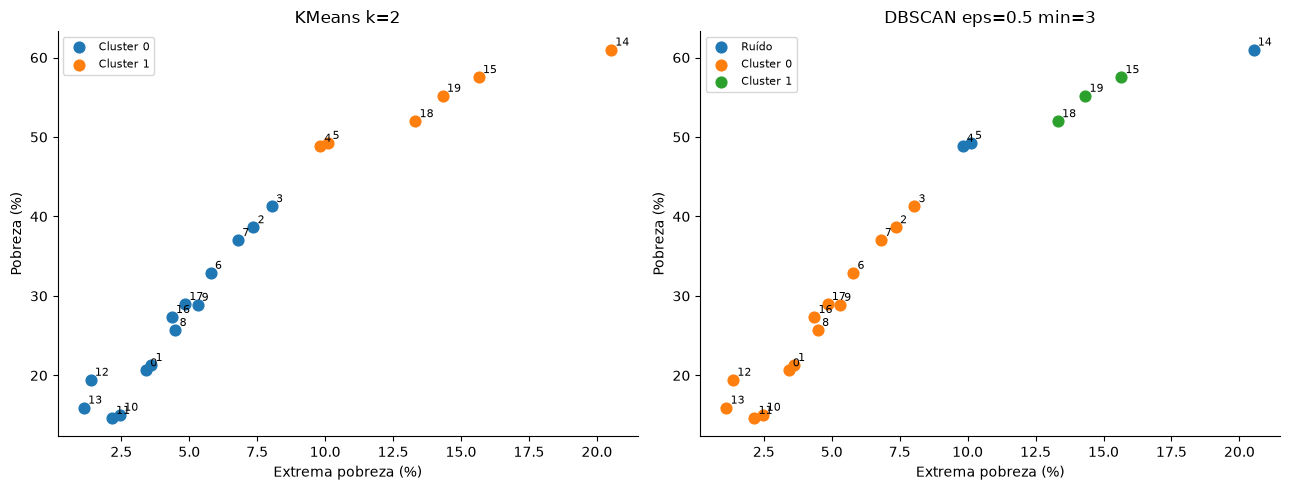

Os números do gráfico correspondem aos índices da tabela de perfis acima.


In [4]:
aris=[]
for seed in range(20):
    labels=KMeans(n_clusters=km.n_clusters,n_init=30,random_state=seed).fit_predict(X)
    aris.append(adjusted_rand_score(km.labels_,labels))
sem_escala=KMeans(n_clusters=km.n_clusters,n_init=30,random_state=42).fit_predict(base[features])
sensibilidade={'ari_min_sementes':min(aris),'ari_medio_sementes':float(np.mean(aris)),
 'ari_sem_padronizacao':adjusted_rand_score(km.labels_,sem_escala)}
display(pd.Series(sensibilidade).to_frame('ARI'))
resumo=base.groupby('cluster_kmeans').agg(perfis=('sexo','size'),extrema_media=('extrema','mean'),pobreza_media=('pobreza','mean'))
display(resumo.round(2))
for c,g in base.groupby('cluster_kmeans'):
    print('Cluster',c,':','; '.join(g.segmento+' / '+g.sexo))
resultado={'kmeans':km_nome,'dbscan':db_nome,'sensibilidade':sensibilidade,'n_perfis':len(base)}
(OUT/'resumo_modelagem.json').write_text(json.dumps(resultado,ensure_ascii=False,indent=2),encoding='utf-8')
fig,axs=plt.subplots(1,2,figsize=(13,5))
for ax,col,titulo in zip(axs,['cluster_kmeans','cluster_dbscan'],[km_nome,db_nome]):
    for c,g in base.groupby(col):
        ax.scatter(g.extrema,g.pobreza,label='Ruído' if c==-1 else f'Cluster {c}',s=60)
        for i,r in g.iterrows(): ax.annotate(str(i),(r.extrema,r.pobreza),fontsize=8,xytext=(3,3),textcoords='offset points')
    ax.set(title=titulo,xlabel='Extrema pobreza (%)',ylabel='Pobreza (%)'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT/'clusters.png',dpi=150); plt.show()
print('Os números do gráfico correspondem aos índices da tabela de perfis acima.')


## Conclusões, uso e limitações
As tabelas executadas acima mostram parâmetros, métricas, membros e médias dos grupos. Essas médias descrevem perfis com peso igual, **não pessoas**. Os rótulos numéricos são arbitrários: não representam classes oficiais, diagnósticos ou uma ordem de prioridade. K-means pode ser usado como resumo visual; o DBSCAN verifica se a hipótese de separação por densidade é plausível. Nenhuma escolha deve ser tratada como descoberta de grupos sociais naturais.

ARI compara partições (1 indica coincidência); a variação de sementes mede apenas estabilidade algorítmica. A comparação sem padronização revela sensibilidade à escala; não substitui avaliação do erro amostral. Mesmo índices altos não demonstram utilidade para políticas públicas. Não há teste de significância entre perfis: correlações e sobreposições exigiriam informações adicionais do desenho amostral.

**Decisões possíveis:** comunicar quais recortes merecem investigação, discutir barreiras de acesso e planejar coleta local. **Uso inadequado:** selecionar beneficiários, atribuir causas, prever efeitos de programas ou afirmar taxas para São Paulo.

**Melhorias até a apresentação:** verificar estabilidade por ano e com perturbações compatíveis com os CV; consultar microdados e pesos/desenho amostral; obter estimativas oficiais de SP com a mesma definição e período; validar utilidade com especialistas. Se a base continuar pequena, manter explicitamente a natureza demonstrativa em vez de buscar apenas índices maiores. A ausência de recorte local, a defasagem histórica, categorias omitidas, agregação e sobreposição limitam generalização.

**Integração com parte 2:** disponibilizar `perfis_clusters.csv`, `metricas_modelos.csv`, `indicadores.json` e gráficos. Mostrar algoritmo, parâmetros, cobertura e limitações junto aos clusters. A interface da parte 2 não foi fornecida nem implementada nesta entrega; sua integração ainda é necessária para o projeto completo.

## Referências
- IBGE: https://ftp.ibge.gov.br/Estatisticas_de_Genero/Indicadores_sociais_das_mulheres_no_Brasil_3a_edicao/xls/1_Empoderamento_Economico_xls.zip
- scikit-learn: https://scikit-learn.org/stable/modules/clustering.html
- Materiais fornecidos: Projeto Parte 3.pdf; ICD - Aula 15.pdf; Aula_15B_Clustering.ipynb; requisitos para apresentação e enunciado da parte 2.
